# Milestone 4 — Score and segment

Mechanical part: R/F/M scores plus an RFM string per customer.
Judgment part: collapse 125 possible score combos into 5 named segments
Marketing can actually campaign to.

Strategy (hybrid, stated up front): quintile scores for comparability,
then explicit named rules evaluated top-down. A composite-sum tier would
mix a `545` with a `455` even though they need different treatments, so
rules win. Same logic lives in `sql/03_rfm_segments.sql` (NTILE mirror);
pandas `qcut` below is authoritative.

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd
import sqlalchemy as sa

engine = sa.create_engine(os.environ["DATABASE_URL"])
print("engine ready")

engine ready


## 1. Score: R and M by quintile, F on a custom 5-scale

R: `qcut(recency, 5)` with 5 = most recent. M: `qcut(monetary, 5)` with
5 = biggest spend. F cannot be quintiled — 4,679 of 8,438 customers sit
exactly at frequency 1, so `qcut` throws duplicate-edge errors. Documented
fix: `1 -> 1, 2-3 -> 2, 4-6 -> 3, 7-12 -> 4, 13+ -> 5`. R and M bins stay
~even; F stays lopsided on purpose.

In [2]:
rfm = pd.read_sql(
    sa.text(
        """
        SELECT o.customer_id,
               (DATE '2026-06-15' - MAX(o.created_at)::DATE) AS recency,
               COUNT(*) AS frequency,
               SUM(o.total) AS monetary
        FROM ecom.orders AS o
        WHERE o.payment_status = 'paid'
        GROUP BY o.customer_id
        """
    ),
    engine,
)
rfm["R"] = pd.qcut(rfm["recency"], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["M"] = pd.qcut(rfm["monetary"], 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["F"] = rfm["frequency"].map(
    lambda f: 1 if f == 1 else 2 if f <= 3 else 3 if f <= 6 else 4 if f <= 12 else 5
)
rfm["rfm"] = rfm["R"].astype(str) + "-" + rfm["F"].astype(str) + "-" + rfm["M"].astype(str)
print(f"rows: {len(rfm)}")
rfm.head()

rows: 8438


,customer_id,recency,frequency,monetary,R,M,F,rfm
0,6114,16,1,4835.64,4,2,1,4-1-2
1,4790,74,2,14033.74,1,3,2,1-2-3
2,3936,72,4,39577.20,1,4,3,1-3-4
3,5761,44,6,51488.12,3,5,3,3-3-5
4,5468,47,1,4126.46,2,2,1,2-1-2


In [3]:
print("R distribution (expect ~even):")
print(rfm["R"].value_counts().sort_index().to_string())
print("\nM distribution (expect ~even):")
print(rfm["M"].value_counts().sort_index().to_string())
print("\nF distribution (expect lopsided — 55% at 1, documented above):")
print(rfm["F"].value_counts().sort_index().to_string())

R distribution (expect ~even):
R
1    1670
2    1688
3    1592
4    1765
5    1723

M distribution (expect ~even):
M
1    1689
2    1691
3    1683
4    1687
5    1688

F distribution (expect lopsided — 55% at 1, documented above):
F
1    4679
2     781
3    1369
4    1115
5     494


## 2. Segment: five named rules, first match wins

| # | Segment | Rule | Plain meaning |
|---|---------|------|---------------|
| 1 | Champions | R>=4, F>=4, M=5 | bought in last ~26d, 7+ orders, top-20% spend |
| 2 | Loyal Heavy Repeaters | F>=4 | 7+ orders, below a champion bar |
| 3 | At-Risk One-Timers | F=1, R<=2 | one order, 44+ days ago |
| 4 | Recent One-Timers | F=1 (rest) | one order within ~6 weeks |
| 5 | Growing Repeaters | remainder | 2-6 orders, mid base |

Thresholds in days come from the R quintile edges (R>=4: recency <= 26d;
R<=2: recency > 44d) and the F map (F>=4: 7+ orders).

In [4]:
def assign(r):
    if r.R >= 4 and r.F >= 4 and r.M == 5:
        return "Champions"
    if r.F >= 4:
        return "Loyal Heavy Repeaters"
    if r.F == 1 and r.R <= 2:
        return "At-Risk One-Timers"
    if r.F == 1:
        return "Recent One-Timers"
    return "Growing Repeaters"

rfm["segment"] = rfm.apply(assign, axis=1)
prof = rfm.groupby("segment").agg(
    n=("customer_id", "count"), revenue=("monetary", "sum"),
    R=("R", "mean"), freq=("frequency", "mean"), spend=("monetary", "mean"),
)
prof["pct_customers"] = prof["n"] / len(rfm) * 100
prof["pct_revenue"] = prof["revenue"] / rfm["monetary"].sum() * 100
print(prof.round(2).to_string())
assert prof["n"].sum() == len(rfm), "customers falling through the rules!"
print("\nNo gaps: segment counts sum to", int(prof["n"].sum()))

                          n       revenue     R   freq      spend  pct_customers  pct_revenue
segment                                                                                      
At-Risk One-Timers     2544  1.881672e+07  1.46   1.00    7396.51          30.15         6.65
Champions               966  1.461830e+08  4.64  19.43  151328.14          11.45        51.68
Growing Repeaters      2150  6.551341e+07  3.26   4.08   30471.35          25.48        23.16
Loyal Heavy Repeaters   643  3.616727e+07  3.26   8.72   56247.70           7.62        12.79
Recent One-Timers      2135  1.617885e+07  3.84   1.00    7577.92          25.30         5.72

No gaps: segment counts sum to 8438


## 3. Read the table

Champions are 11% of customers and 52% of revenue — the concentration
Milestone 3 predicted. Growing Repeaters (2-6 orders) hold another 23% of
revenue and are the promotion audience. One-timers split cleanly by
recency: recent ones can still convert, stale ones need win-back or
deprioritising. Plots below are the same numbers, for the brief.

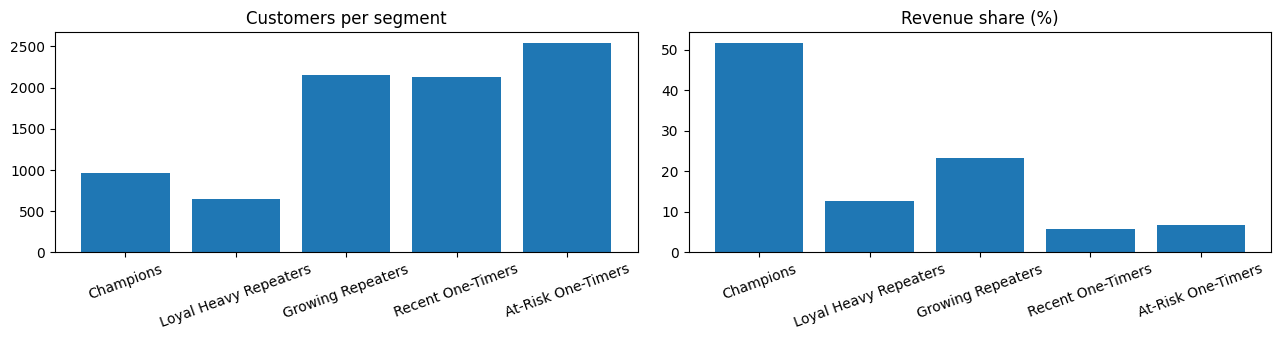

In [5]:
%matplotlib inline
order = ["Champions", "Loyal Heavy Repeaters", "Growing Repeaters",
         "Recent One-Timers", "At-Risk One-Timers"]
p = prof.loc[order]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
axes[0].bar(p.index, p["n"])
axes[0].set_title("Customers per segment")
axes[0].tick_params(axis="x", rotation=20)
axes[1].bar(p.index, p["pct_revenue"])
axes[1].set_title("Revenue share (%)")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

## Notes (wrong turn + handoff)

- Wrong turn kept: my first Champions rule (`R>=4, F>=3, M>=4`) caught
  21.6% of customers — a "VIP" segment with one in five customers is a
  contradiction. Tightened to `M=5, F>=4` (top-quintile spend, 7+ orders)
  and it fell to a credible 11.5% holding half the revenue.
- Handoff to Milestone 5: the brief goes Marketing-facing next. Open
  questions I am carrying over: whether At-Risk One-Timers are worth a
  win-back budget at all (6.7% of revenue), and what second-purchase
  trigger converts Recent One-Timers before they slide stale.